# 🚀 Practice Day 56

**📅 Date:** 2026-11-06  
**📁 Category:** Phase 1 · NumPy 기초 (Round 5/5)


---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice vectorized NumPy operations by implementing a weight-based tiered parcel delivery fee formula
  (무게 구간별 택배 배송비 계산식을 벡터화된 NumPy 연산으로 구현하며 배열 연산 연습하기)
- Find how fees are distributed, how many parcels fall into each weight tier, and what the average/highest fee is
  (요금이 어떻게 분포하는지, 각 무게 구간에 몇 건씩 속하는지, 평균/최고 요금은 얼마인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Parcel Delivery Fee Calculation (Weight-Tiered) / 택배 배송비 계산 데이터 (무게 구간별 요금)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 220 parcels — single table with only `parcel_id` and `weight_kg`. The fee needs to be computed with vectorized array operations using the rate structure below.

**Rate structure / 요금 구조 (USD):**
- Up to 2kg: $3 (2kg 이하: $3)
- 2–5kg: $5 (2~5kg: $5)
- 5–10kg: $8 (5~10kg: $8)
- Over 10kg: $8 + $0.50 per additional kg (10kg 초과: $8 + 초과 kg당 $0.50)

(220개 택배의 무게 데이터입니다 — parcel_id와 weight_kg만 있는 단일 테이블이며, 배송비는 위 요금 구조를 벡터화 연산으로 직접 계산해야 합니다.)

## Dataset Preview

In [50]:
# Dataset Preview
import numpy as np
import pandas as pd

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate parcel weights (fee is NOT precomputed) ---
n = 220
tier_choice = rng.choice(['t1', 't2', 't3', 't4'], size=n, p=[0.28, 0.32, 0.25, 0.15])
weight = np.zeros(n)
for i, t in enumerate(tier_choice):
    if t == 't1':
        weight[i] = rng.uniform(0.1, 2.0)
    elif t == 't2':
        weight[i] = rng.uniform(2.01, 5.0)
    elif t == 't3':
        weight[i] = rng.uniform(5.01, 10.0)
    else:
        weight[i] = rng.uniform(10.01, 25.0)
weight = np.round(weight, 1)

df = pd.DataFrame({
    'parcel_id': [f'PC{str(i+1).zfill(4)}' for i in range(n)],
    'weight_kg': weight
})

df.head(10)


,parcel_id,weight_kg
0,PC0001,6.5
1,PC0002,3.5
2,PC0003,19.9
3,PC0004,9.8
4,PC0005,0.6
5,PC0006,23.9
6,PC0007,5.1
7,PC0008,7.8
8,PC0009,1.3
9,PC0010,2.3


## Dataset Information

In [51]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   parcel_id  220 non-null    str    
 1   weight_kg  220 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.6 KB

Shape: (220, 2)


,parcel_id,weight_kg
count,220,220.000000
unique,220,NaN
top,PC0001,NaN
freq,1,NaN
mean,NaN,5.744091
std,NaN,5.793305
min,NaN,0.100000
25%,NaN,1.700000
50%,NaN,3.900000
75%,NaN,8.000000


---
# ❓ Business Questions

1. **(Analysis)** Using the rate structure above, what is the delivery fee for each parcel?
   (위 요금 구조를 적용하면, 택배별 배송비는 각각 얼마인가?)
2. **(Analysis)** How many parcels fall into each weight tier (≤2kg, 2-5kg, 5-10kg, >10kg)?
   (각 무게 구간(2kg 이하/2~5kg/5~10kg/10kg 초과)에 속하는 택배는 몇 건인가?)
3. **(Analysis)** What is the average fee across all parcels, and which parcel has the highest fee?
   (전체 평균 배송비는 얼마이며, 가장 요금이 높은 택배는 무엇인가?)
4. **(Visualization)** Show the distribution of delivery fees across all parcels.
   (전체 택배의 배송비 분포는 어떤 모습인가?)
5. **(Visualization)** Show the relationship between weight and fee — where do the tier boundaries become visible?
   (무게와 배송비의 관계를 보면, 구간 경계가 어디서 드러나는가?)

---
# 🔍 Data Cleaning Check


In [52]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
parcel_id    0
weight_kg    0
dtype: int64

Duplicate rows: 0

Dtypes
parcel_id        str
weight_kg    float64
dtype: object

Column names
['parcel_id', 'weight_kg']

Text columns — unique counts
parcel_id    220
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Using the rate structure, what is the delivery fee for each parcel? (요금 구조 적용 시 택배별 배송비는?)

**Result:**  
Printed rows follow the tiers: PC0005 (0.6 kg) is **$3.00**, PC0002 (3.5 kg) is **$5.00**, PC0001 (6.5 kg) is **$8.00**, and PC0003 (19.9 kg) is **$12.95**.  
(출력된 행도 구간을 따릅니다. PC0005(0.6kg)는 **$3.00**, PC0002(3.5kg)는 **$5.00**, PC0001(6.5kg)는 **$8.00**, PC0003(19.9kg)는 **$12.95**입니다.)  

**Insight:**  
Fees stay flat inside a tier. Only weights over 10 kg go above **$8.00**, such as PC0219 at 21.2 kg with **$13.60**.  
(구간 안에서는 요금이 같습니다. 10kg를 넘는 무게만 **$8.00**을 넘고, 21.2kg인 PC0219는 **$13.60**입니다.)

In [53]:
# Question 1: compute the delivery fee for every row using the rate structure (vectorized - no row-by-row loop)
weight = df['weight_kg'].to_numpy()

df['fee'] = np.select(
    [weight <= 2, weight <= 5, weight <= 10],
    [3, 5, 8],
    default=8 + 0.5 * (weight - 10),
)

df

,parcel_id,weight_kg,fee
0,PC0001,6.5,8.00
1,PC0002,3.5,5.00
2,PC0003,19.9,12.95
3,PC0004,9.8,8.00
4,PC0005,0.6,3.00
...,...,...,...
215,PC0216,6.0,8.00
216,PC0217,0.3,3.00
217,PC0218,1.1,3.00
218,PC0219,21.2,13.60


## Question 2

**Question:** How many parcels fall into each weight tier? (구간별 택배 건수는?)

**Result:**  
The 2–5 kg tier has the most parcels at **71**, and the over-10 kg tier has the least at **27**. The other counts are **64** (≤2 kg) and **58** (5–10 kg).  
(2–5kg 구간이 **71**건으로 가장 많고, 10kg 초과가 **27**건으로 가장 적습니다. 나머지는 2kg 이하 **64**건, 5–10kg **58**건입니다.)  

**Insight:**  
The four counts add up to **220** parcels. The largest tier has **44** more parcels than the smallest (71 − 27).  
(네 구간의 합은 **220**건입니다. 가장 많은 구간이 가장 적은 구간보다 **44**건 많습니다.)

In [54]:
# Question 2: how many parcels fall into each weight tier
print("≤2kg",(df['weight_kg'] <= 2).sum())
print("2-5kg", ((df['weight_kg'] > 2) & (df['weight_kg'] <=5)).sum())
print("5-10kg", ((df['weight_kg'] > 5) & (df['weight_kg'] <=10)).sum())
print(">10kg", (df['weight_kg'] > 10).sum())

≤2kg 64
2-5kg 71
5-10kg 58
>10kg 27


## Question 3

**Question:** What is the average fee across all parcels, and which parcel has the highest fee? (평균 요금과 최고 요금 택배는?)

**Result:**  
The average fee is **$6.118**, and the highest fee is **$15.10** for PC0100 at 24.2 kg.  
(평균 요금은 **$6.118**이고, 최고 요금은 24.2kg인 PC0100의 **$15.10**입니다.)  

**Insight:**  
PC0100 is **$0.10** above the next parcel, PC0162 at **$15.00** (24.0 kg).  
(PC0100은 다음 택배인 PC0162(**$15.00**, 24.0kg)보다 **$0.10** 높습니다.)

In [55]:
# Question 3: average fee, and which parcel has the highest fee
print(df['fee'].mean(), df['fee'].max())
df.sort_values('fee', ascending=False).head(5)

6.118409090909092 15.1


,parcel_id,weight_kg,fee
99,PC0100,24.2,15.10
161,PC0162,24.0,15.00
5,PC0006,23.9,14.95
72,PC0073,23.9,14.95
181,PC0182,23.8,14.90


---
# 📈 Visualization

**Chart 1:** Histogram — distribution of delivery fees (히스토그램: 배송비 분포)

*Interpretation:*  
The tall bars sit at the flat tier fees **$3**, **$5**, and **$8**, and a thin tail of higher fees runs out toward **$15**.  
(높은 막대는 고정 요금 **$3**, **$5**, **$8**에 있고, 그보다 높은 요금은 **$15** 쪽으로 얇게 이어집니다.)  

---

**Chart 2:** Scatter plot — weight vs fee, showing the tier structure (산점도: 무게 vs 배송비, 구간 구조 확인)

*Interpretation:*  
The fee is flat at **$3**, **$5**, and **$8** until the dashed lines at 2 kg, 5 kg, and 10 kg, then it rises. The highest point is PC0100 at **$15.10** (24.2 kg).  
(점선인 2kg, 5kg, 10kg까지 요금은 **$3**, **$5**, **$8**로 평평하다가 그 뒤부터 올라갑니다. 가장 높은 점은 24.2kg인 PC0100의 **$15.10**입니다.)


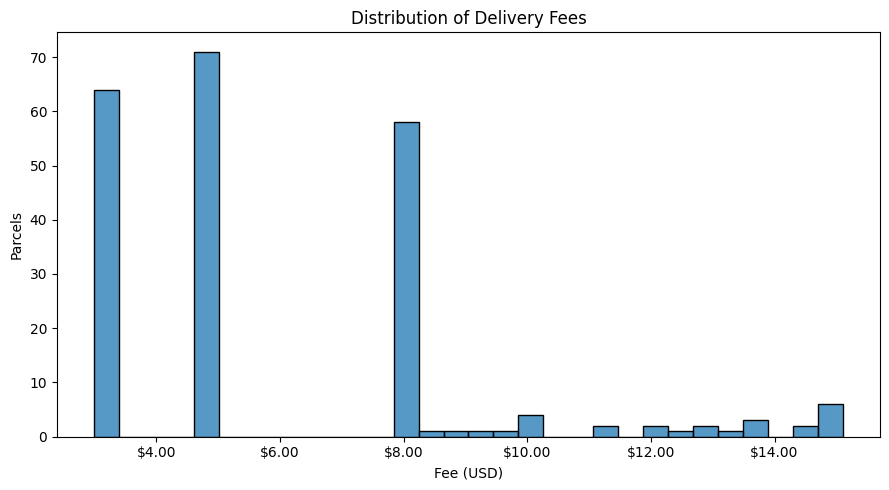

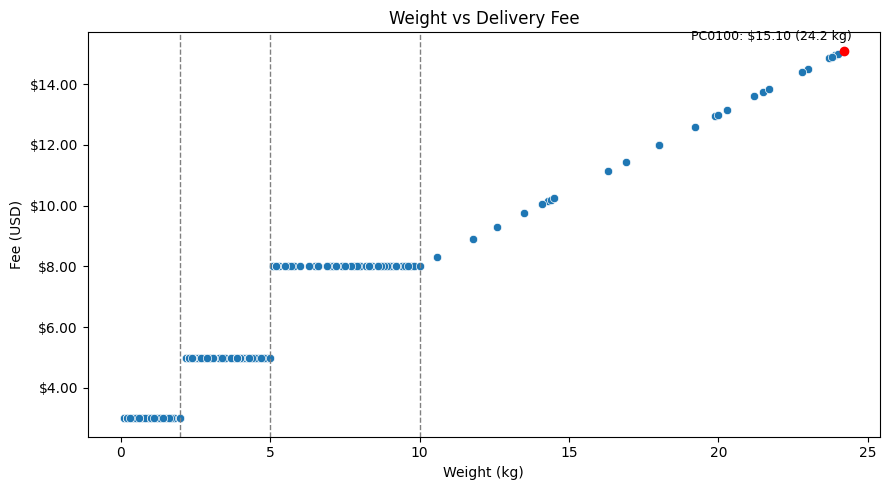

In [56]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: distribution of delivery fees (histogram)
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['fee'], bins=30, ax=ax)
ax.set_title('Distribution of Delivery Fees')
ax.set_xlabel('Fee (USD)')
ax.set_ylabel('Parcels')
ax.xaxis.set_major_formatter('${x:,.2f}')
plt.tight_layout()
plt.show()

# Chart 2: weight vs fee (scatter) - flat tiers, then a rising slope after 10kg
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(x='weight_kg', y='fee', data=df, ax=ax)
for kg in (2, 5, 10):
    ax.axvline(kg, color='gray', linestyle='--', linewidth=1)
ax.set_title('Weight vs Delivery Fee')
ax.set_xlabel('Weight (kg)')
ax.set_ylabel('Fee (USD)')
ax.yaxis.set_major_formatter('${x:,.2f}')
top = df.loc[df['fee'].idxmax()]
ax.scatter(top['weight_kg'], top['fee'], color='red', zorder=3)
ax.annotate(
    f"{top['parcel_id']}: ${top['fee']:.2f} ({top['weight_kg']} kg)",
    (top['weight_kg'], top['fee']),
    textcoords='offset points', xytext=(-110, 8), fontsize=9,
)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Most parcels pay a flat tier fee, and only **27** parcels are over 10 kg.  
  (대부분 택배가 구간 고정 요금을 내고, 10kg를 넘는 택배는 **27**건입니다.)  
- The average fee is **$6.118**, while the highest single fee is **$15.10** (PC0100, 24.2 kg).  
  (평균 요금은 **$6.118**이고, 가장 높은 요금은 PC0100(24.2kg)의 **$15.10**입니다.)  
- The 2–5 kg tier is the largest group, with **71** parcels.  
  (2–5kg 구간이 **71**건으로 가장 많습니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat the three flat tiers separately from the over-10 kg slope, since weight inside a tier does not change the fee.  
   (구간 안에서는 무게가 달라도 요금이 같으므로, 고정 요금 세 구간과 10kg 초과 기울기를 따로 봅니다.)  
2. Review the heaviest parcels first. PC0100 is the top fee at **$15.10**, and the next shown fees are **$15.00** and **$14.95**.  
   (가장 무거운 택배부터 봅니다. PC0100이 **$15.10**으로 1위이고, 그다음은 **$15.00**, **$14.95**입니다.)  
3. Expect most volume in the 2–5 kg tier (**71** of **220** parcels).  
   (물량의 중심은 2–5kg 구간입니다. **220**건 중 **71**건입니다.)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- I started with a nested `np.where` and was not sure that was the clearest way to code four tiers.  
  (네 구간을 겹친 `np.where`로 시작했고, 그게 가장 읽기 쉬운 방법인지 확신이 없었습니다.)  
- I thought Question 2 needed a tier column and a groupby.  
  (Question 2에 구간 열을 만들고 groupby를 해야 한다고 생각했습니다.)  
-   


---
# ✅ What I Learned
*Today's biggest lesson*

- `np.select` assigns the first matching tier, so the conditions can be ordered from the lightest weight.  
  (`np.select`는 처음 맞는 구간을 쓰므로, 조건을 가벼운 무게부터 나열하면 됩니다.)  
- A boolean condition's `.sum()` counts the rows in that tier, without a new column.  
  (조건의 `.sum()`이 그 구간 건수라서, 열을 새로 만들지 않아도 됩니다.)  
-   


---
# 🧠 Reflection

**What was difficult?**  
Coding the four weight tiers and counting parcels per tier.  
(무게 구간 네 개를 코드로 쓰고 구간별 건수를 세는 것)

**Why?**  
Nested `np.where` gets deep with four tiers, and I thought Question 2 needed a tier column and a `groupby`.  
(구간이 네 개면 `np.where`를 겹칠수록 깊어지고, Question 2에 구간 열과 `groupby`가 필요하다고 생각함)

**How did I solve it?**  
Used `np.select` with the conditions ordered from the lightest weight, and counted each tier with a boolean condition's `.sum()`.  
(가벼운 무게부터 조건을 나열한 `np.select`를 쓰고, 구간 건수는 조건의 `.sum()`으로 셈)

**What would I do differently next time?**  
Use the same boundaries for the fee and the counts, and check that the counts add up to the row count.  
(요금과 건수에 같은 경계를 쓰고, 건수의 합이 행 수와 같은지 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The tier formula and the tier counts both came out consistent.  
(요금 식과 구간 건수가 서로 맞게 나왔습니다.)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★★☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 57: Data cleaning  
  (Day 57: 데이터 클리닝)  
